In [2]:
#Imports

%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys
import html as html_lib
from IPython.display import HTML, display as ipy_display
import matplotlib.pyplot as plt
from datasets import load_dataset

root = Path.cwd().resolve()
root = root.parent
sys.path.insert(0, str(root))

import torch
from collections import defaultdict
from transformers import AutoTokenizer, AutoModelForCausalLM
from sae_trainer.core.model_utils import SparseAutoencoder, ReluSparseAutoencoder, TopKSparseAutoencoder
from sae_trainer.sae_semantic_eval.feature_tracer_utils import FeatureTracer, TraceConfig
from sae_trainer.sae_semantic_eval.feature_tracer_eval_utils import top_n_feats_by_hits_count, top_n_feats_by_act_mass, prompt_x_feature_heatmap, feature_token_position_profile, top_m_feature_coactivation, render_feature_card, plot_feature_umap, plot_inter_feature_similarity, plot_feature_similarity_violins, plot_feature_specificity_scatter


/Users/alyssagardiner/src/sae_trainer/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Do not change - load example SAE

device = "cuda" if torch.cuda.is_available() else "cpu"
model_name = "Qwen/Qwen2-0.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(model_name)
llm = AutoModelForCausalLM.from_pretrained(model_name).to(device).eval()

# Load SAE checkpoint — pick whichever layer you want to analyse (3, 6, 9, or 11)
ckpt = torch.load(root / "model_weights_files/topk_sae_qwen_openwebtext_layer12.pt", map_location=device)
sae = TopKSparseAutoencoder(d_in=ckpt["d_in"], d_latent=ckpt["d_latent"], k=40, normalize_decoder=True).to(device)

sae.load_state_dict(ckpt["model_state"])
sae.eval()

TopKSparseAutoencoder(
  (encoder): Linear(in_features=896, out_features=7168, bias=True)
  (decoder): Linear(in_features=7168, out_features=896, bias=False)
)

In [4]:
# Build TraceConfig and FeatuerTracer. Keep defaults to reproduce published results
cfg = TraceConfig(
    layer_idx=12,
    topk_per_token=8,
    min_activation=0.01,
    max_new_tokens=10,
    do_sample=True,
    temperature=0.7,
    token_mode='generated_only',
    min_prompts=10
)
tracer = FeatureTracer(llm, tokenizer, sae, device, cfg)

In [5]:
# Build openwebtext dataset and FeatureTracer summaries. Keep defaults to reproduce published results

n_train_docs = 4000 # cfg.max_batches * cfg.collection_batch_size

ds = load_dataset("openwebtext", split="train", streaming=True)
# Exclude training data
ds = ds.skip(n_train_docs)

summaries = tracer.trace_prompts_from_iterable_dataset(ds, max_prompts_to_trace=1000)

In [6]:
# Score all features and display the top 20 SAE features ranked by feature_context_specificity_score
scores = tracer.feature_specificity_scores()
display(scores.head(20))

,feature_id,hits,n_prompts,mean_activation,context_specificity,token_specificity,context_specificity_vs_baseline,token_specificity_vs_baseline,firing_rate,composite_score
0,6899,26,10,3.233498,0.365929,0.392907,0.299533,0.061771,0.002892,0.668031
1,5461,68,23,4.098023,0.278628,0.592076,0.212232,0.260940,0.007563,1.155578
2,3554,43,20,3.844119,0.222219,0.576537,0.155823,0.245401,0.004783,0.898125
3,454,23,12,3.123096,0.211953,0.359192,0.145557,0.028056,0.002558,0.434326
4,5814,26,14,4.966279,0.207258,0.642004,0.140862,0.310868,0.002892,1.157382
5,6315,103,37,3.775048,0.198215,0.408554,0.131819,0.077418,0.011456,0.608299
6,6865,65,34,3.228820,0.197239,0.394920,0.130843,0.063784,0.007229,0.497453
7,3531,277,87,2.581501,0.196901,0.372648,0.130505,0.041512,0.030809,0.366297
8,443,574,88,3.615331,0.194709,0.345475,0.128313,0.014339,0.063842,0.447291
9,6529,63,32,5.055991,0.185607,0.718079,0.119211,0.386943,0.007007,1.110164


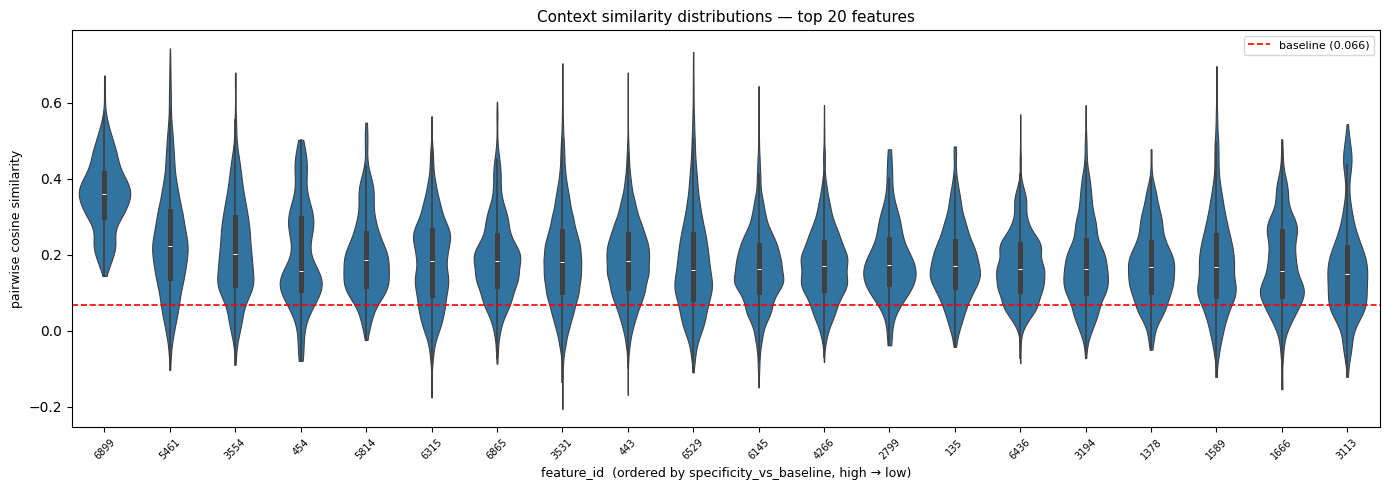

In [7]:
# Plot pairwise cosine similarity metrics for the activating contxts of the top 20 SAE features ranked by feature_context_specificity_score
plot_feature_similarity_violins(tracer, top_n=20, specificity_type='context')

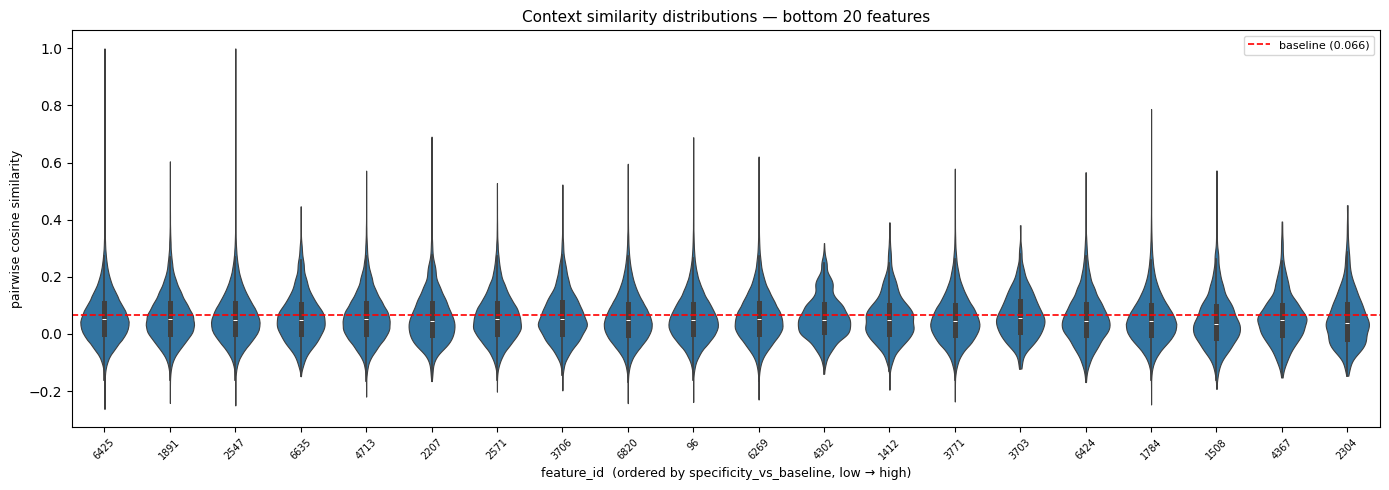

In [8]:
# Plot pairwise cosine similarity metrics for the activating contxts of the top 20 SAE features ranked by feature_context_specificity_score
# Note that the pairwise scores tend to hover between 0.0 and 'baseline'
plot_feature_similarity_violins(tracer, top_n=None, bottom_n=20, specificity_type='context')

In [9]:
# Plot the feature specificity score scatter plot
# y-axis: feature_token_specificity_score
# x-axis: feature_context_specificity_score
# color: composite_score
# size: firing_rate
# Note: feature interpretability tends to increase as you move up and to the right in this plot
plot_feature_specificity_scatter(tracer, top_n=None, size_by="firing_rate")

In [10]:
# Plot the feature specificity score scatter plot
# y-axis: feature_token_specificity_score
# x-axis: feature_context_specificity_score
# color: composite_score
# size: firing_rate
# Note: darker circles near the bottom-left quandrant highlight non-specific, "noisy" features
plot_feature_specificity_scatter(tracer, top_n=None, size_by="composite_score")

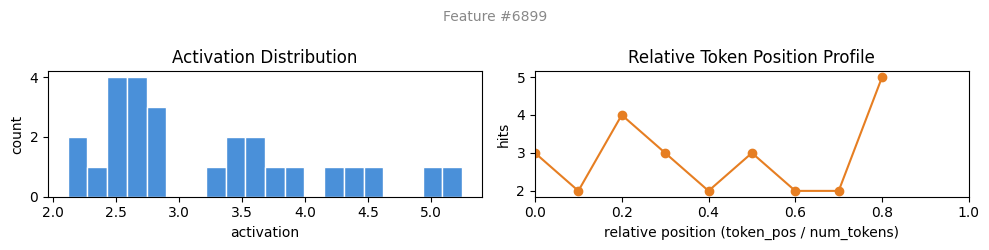

In [12]:
# Render feature card for a given feature_id
# Note: hover over a bubble in the feature specificity landscape plot to see its feature_id
render_feature_card(6899, tracer, top_n=10)

In [ ]:
#from sae_trainer.sae_semantic_eval.feature_tracer_export_utils import export_feature_docs
#export_feature_docs(tracer, docs_dir="../docs")

Saved 336 features → ../docs/feature_scores.csv
Saved 336 feature cards → ../docs/feature_cards.json

Docs exported to ../docs/
  feature_scores.csv  — scatter plot data (one row per feature)
  feature_cards.json  — card data keyed by feature_id (str)
